## Package and Setup



### Packages

In [2]:
!pip install -q sentencepiece "transformers<5.0.0" selfcheckgpt accelerate tqdm accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import numpy as np
import spacy
import torch
from transformers import pipeline
import json
import random
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from selfcheckgpt.modeling_selfcheck import SelfCheckNLI
from selfcheckgpt.modeling_selfcheck import SelfCheckLLMPrompt
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, roc_curve
import matplotlib.pyplot as plt
from tqdm import tqdm
import re
from sklearn.metrics import cohen_kappa_score
import pandas as pd
from IPython.display import display

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### Set device, nlp and selfcheck_nli

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
nlp = spacy.load("en_core_web_sm")
selfcheck_nli = SelfCheckNLI(device=device)

tokenizer_config.json:   0%|          | 0.00/400 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/883 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.74G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.74G [00:00<?, ?B/s]

SelfCheck-NLI initialized to device cuda


# Replication of Original work (on WikiBio Dataset)

### Test run to check packages works

In [ ]:
# Define your text variables
sample1 = "Michael Alan Weiner (born March 31, 1942) is an American radio host. He is the host of The Savage Country."
sample2 = "Michael Alan Weiner (born January 13, 1960) is a Canadian radio host. He works at The New York Times."
sample3 = "Michael Alan Weiner (born March 31, 1942) is an American radio host. He obtained his PhD from MIT."

passage = "Michael Alan Weiner (born March 31, 1942) is an American radio host. He is the host of The Savage Nation."

sampled_summaries = [sample1, sample2, sample3]
sentences = [sent.text.strip() for sent in nlp(passage).sents if len(sent.text.strip()) > 3]

# Predict hallucination scores
print("Evaluating sentences...")
sent_scores_nli = selfcheck_nli.predict(
    sentences=sentences,
    sampled_passages=sampled_summaries
)

for sentence, score in zip(sentences, sent_scores_nli):
  # Scores range from 0.0 to 1.0; higher scores indicate a higher probability of hallucination
  print(f"Score: {score:.4f} | Sentence: {sentence}")

Evaluating sentences...
Score: 0.3340 | Sentence: Michael Alan Weiner (born March 31, 1942) is an American radio host.
Score: 0.9751 | Sentence: He is the host of The Savage Nation.


### Load wiki_bio_gpt3_hallucination data

In [ ]:
dataset = load_dataset("potsawee/wiki_bio_gpt3_hallucination", split="evaluation")

label_mapping = {
    'accurate': 0.0,
    'minor_inaccurate': 0.5,
    'major_inaccurate': 1.0,
}

human_label_detect_False   = {}
human_label_detect_False_h = {}
human_label_detect_True    = {}
for i_ in range(len(dataset)):
    dataset_i = dataset[i_]
    idx = dataset_i['wiki_bio_test_idx']
    raw_label = np.array([label_mapping[x] for x in dataset_i['annotation']])
    human_label_detect_False[idx] = (raw_label > 0.499).astype(np.int32).tolist()
    human_label_detect_True[idx]  = (raw_label < 0.499).astype(np.int32).tolist()
    average_score = np.mean(raw_label)
    if average_score < 0.99:
        human_label_detect_False_h[idx] = (raw_label > 0.99).astype(np.int32).tolist()

### Experimental Setup

In [ ]:

def unroll_pred(scores, indices):
    unrolled = []
    for idx in indices:
        unrolled.extend(scores[idx])
    return unrolled

def get_PR_with_human_labels(preds, human_labels, pos_label=1, oneminus_pred=False):
    indices = [k for k in human_labels.keys()]
    unroll_preds = unroll_pred(preds, indices)
    if oneminus_pred:
        unroll_preds = [1.0-x for x in unroll_preds]
    unroll_labels = unroll_pred(human_labels, indices)
    assert len(unroll_preds) == len(unroll_labels)
    print("len:", len(unroll_preds))
    P, R, thre = precision_recall_curve(unroll_labels, unroll_preds, pos_label=pos_label)
    return P, R

def print_AUC(P, R):
    print("AUC: {:.2f}".format(auc(R, P)*100))

indices = [x['wiki_bio_test_idx'] for x in dataset]

selfcheck_scores = {} # sentence-level scores
for i in tqdm(range(len(dataset))):
    x = dataset[i]
    idx = dataset[i]['wiki_bio_test_idx']
    selfcheck_scores[idx] = selfcheck_nli.predict(
        sentences = x['gpt3_sentences'],           # list of sentences
        sampled_passages = x['gpt3_text_samples'], # list of sampled passages
    ).tolist()

100%|██████████| 238/238 [57:17<00:00, 14.44s/it]


### Experiment 1: Detecting False

len: 1908
-----------------------
SelfCheckGPT-NLI on WikiBio
AUC: 92.50


Text(0.5, 0, 'Recall')

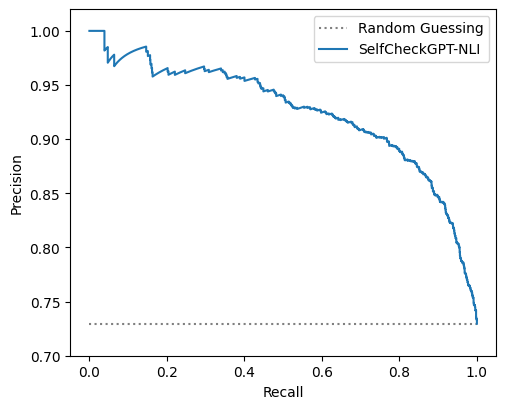

In [ ]:
# with human label, Detecting False
Prec, Rec = get_PR_with_human_labels(selfcheck_scores, human_label_detect_False, pos_label=1)
print("-----------------------")
print("SelfCheckGPT-NLI on WikiBio")
print_AUC(Prec, Rec)

arr = []
for v in human_label_detect_False.values():
    arr.extend(v)
random_baseline = np.mean(arr)
random_baseline

# with human label, Detecting Non-factual
plt.figure(figsize=(5.5, 4.5))
plt.hlines(y=random_baseline, xmin=0, xmax=1.0, color='grey', linestyles='dotted', label='Random Guessing')
plt.plot(Rec, Prec, '-', label='SelfCheckGPT-NLI')
plt.legend()
plt.ylim(0.7,1.02)
plt.ylabel("Precision")
plt.xlabel("Recall")

### Experiment2: Detect False* (harder/less-trivial)

len: 1632
-----------------------
SelfCheckGPT-NLI on WikiBio
AUC: 45.17


Text(0.5, 0, 'Recall')

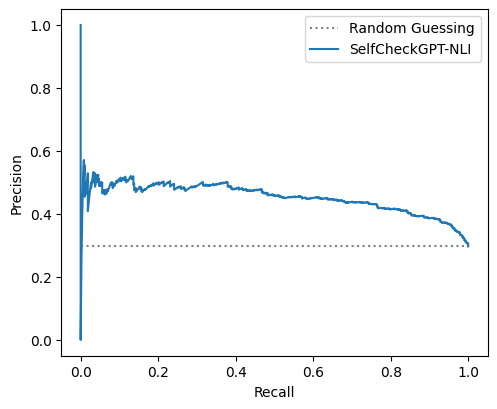

In [ ]:
# with human label, Detecting False
Prec, Rec = get_PR_with_human_labels(selfcheck_scores, human_label_detect_False_h, pos_label=1)
print("-----------------------")
print("SelfCheckGPT-NLI on WikiBio")
print_AUC(Prec, Rec)

arr = []
for v in human_label_detect_False_h.values():
    arr.extend(v)
random_baseline = np.mean(arr)
random_baseline

# with human label, Detecting Non-factual*
plt.figure(figsize=(5.5, 4.5))
plt.hlines(y=random_baseline, xmin=0, xmax=1.0, color='grey', linestyles='dotted', label='Random Guessing')
plt.plot(Rec, Prec, '-', label='SelfCheckGPT-NLI')
plt.legend()
plt.ylabel("Precision")
plt.xlabel("Recall")

### Experiment 3: Detecting True

len: 1908
-----------------------
SelfCheckGPT-NLI on WikiBio
AUC: 66.08


Text(0.5, 0, 'Recall')

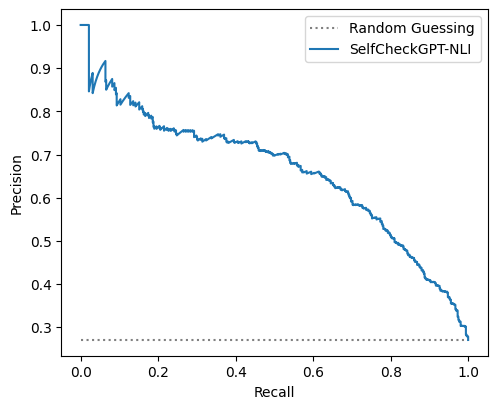

In [ ]:
# with human label, Detecting True
Prec, Rec = get_PR_with_human_labels(selfcheck_scores, human_label_detect_True, pos_label=1, oneminus_pred=True)
print("-----------------------")
print("SelfCheckGPT-NLI on WikiBio")
print_AUC(Prec, Rec)

arr = []
for v in human_label_detect_True.values():
    arr.extend(v)
random_baseline = np.mean(arr)
random_baseline

# with human label, Detecting Non-factual*
plt.figure(figsize=(5.5, 4.5))
plt.hlines(y=random_baseline, xmin=0, xmax=1.0, color='grey', linestyles='dotted', label='Random Guessing')
plt.plot(Rec, Prec, '-', label='SelfCheckGPT-NLI')
plt.legend()
plt.ylabel("Precision")
plt.xlabel("Recall")

# Run on Existing (XSum) dataset

Load XSum Dataset

In [ ]:
xsum_dataset = load_dataset("EdinburghNLP/xsum", split="test")

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/300M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/16.4M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/16.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/204045 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11332 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11334 [00:00<?, ? examples/s]

### Run on XSum dataset

In [ ]:
model_name = "Qwen/Qwen2.5-1.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype="auto", device_map="auto")


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
def generate_summary(article_text: str, temperature: float, num_samples: int = 1):
    prompt = f"Summarize the following article in a few sentences:\n\n{article_text}:\n\nSummary:"
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(model.device)

    do_sample = temperature > 0.0

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=do_sample,
            temperature=temperature if do_sample else None,
            num_return_sequences=num_samples,
            pad_token_id=tokenizer.eos_token_id
        )

    responses = [tokenizer.decode(out[inputs.input_ids.shape[1]:], skip_special_tokens=True).strip() for out in outputs]
    return responses[0] if num_samples == 1 else responses

#### LLM Judge Functionality

In [ ]:
def llm_judge_factuality(sentence: str, reference_text: str) -> int:
    prompt = (
        "You are an expert fact-checker. Determine if the SENTENCE is completely supported by the REFERENCE_TEXT. "
        "Respond with exactly '0' if it is factually supported, or '1' if it contains any hallucination or unsupported facts.\n\n"
        f"REFERENCE_TEXT: {reference_text}\n\n"
        f"SENTENCE: {sentence}\n\n"
        "Output ONLY 0 or 1:"
    )

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(model.device)
    with torch.no_grad():
        # Updated line: use do_sample=False instead of temperature=0.0
        outputs = model.generate(**inputs, max_new_tokens=5, do_sample=False)

    response = tokenizer.decode(outputs[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()

    # Extract 0 or 1 from the response
    match = re.search(r'[01]', response)
    return int(match.group()) if match else 1

#### Run test

In [ ]:
# Scale up evaluation to a subset of XSum for statistically significant results
xsum_subset = xsum_dataset.select(range(50))

xsum_y_true = []
xsum_y_pred = []

print("Running batch evaluation on XSum subset...")
for article in tqdm(xsum_subset):
    source_text = article["document"]

    # 1. Generate Main Summary and Samples
    main_summary = generate_summary(source_text, temperature=0.0, num_samples=1)
    stochastic_samples = generate_summary(source_text, temperature=1.0, num_samples=4)

    # 2. Extract Sentences
    sentences = [sent.text.strip() for sent in nlp(main_summary).sents if len(sent.text.strip()) > 3]
    if not sentences:
        continue

    # 3. Predict Hallucination Scores (SelfCheckGPT)
    sent_scores_nli = selfcheck_nli.predict(
        sentences=sentences,
        sampled_passages=stochastic_samples
    )

    # 4. Generate Ground Truth using LLM-as-a-Judge
    for sent, score in zip(sentences, sent_scores_nli):
        truth_label = llm_judge_factuality(sent, source_text)
        xsum_y_true.append(truth_label)
        xsum_y_pred.append(score)

# 5. Evaluate XSum Results
if len(set(xsum_y_true)) > 1:
    xsum_roc_auc = roc_auc_score(xsum_y_true, xsum_y_pred)
    precision, recall, _ = precision_recall_curve(xsum_y_true, xsum_y_pred)
    xsum_pr_auc = auc(recall, precision)

    print("\n=== XSum Existing Dataset Results ===")
    print(f"Total Sentences Evaluated: {len(xsum_y_true)}")
    print(f"XSum ROC-AUC: {xsum_roc_auc:.4f}")
    print(f"XSum PR-AUC:  {xsum_pr_auc:.4f}")
else:
    print("\nSkipping AUC calculation: Only one class present in LLM-Judge labels.")

Running batch evaluation on XSum subset...


100%|██████████| 50/50 [23:13<00:00, 27.87s/it]


=== XSum Existing Dataset Results ===
Total Sentences Evaluated: 235
XSum ROC-AUC: 0.6280
XSum PR-AUC:  0.4216


In [ ]:
print(xsum_y_true)
print(xsum_y_pred)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]
[np.float64(0.3076680963858962), np.float64(0.7004314363002777), np.float64(0.4900329800148029), np.float64(0.734642653085757), np.float64(0.8942288756370544), np.float64(0.8919985443353653), np.float64(0.9188149571418762), np.float64(0.4946962958201766), np.float64(0.5471123233437538), np.flo


=== XSum Existing Dataset Results ===
Total Sentences Evaluated: 235
XSum ROC-AUC: 0.6280
XSum PR-AUC:  0.4216


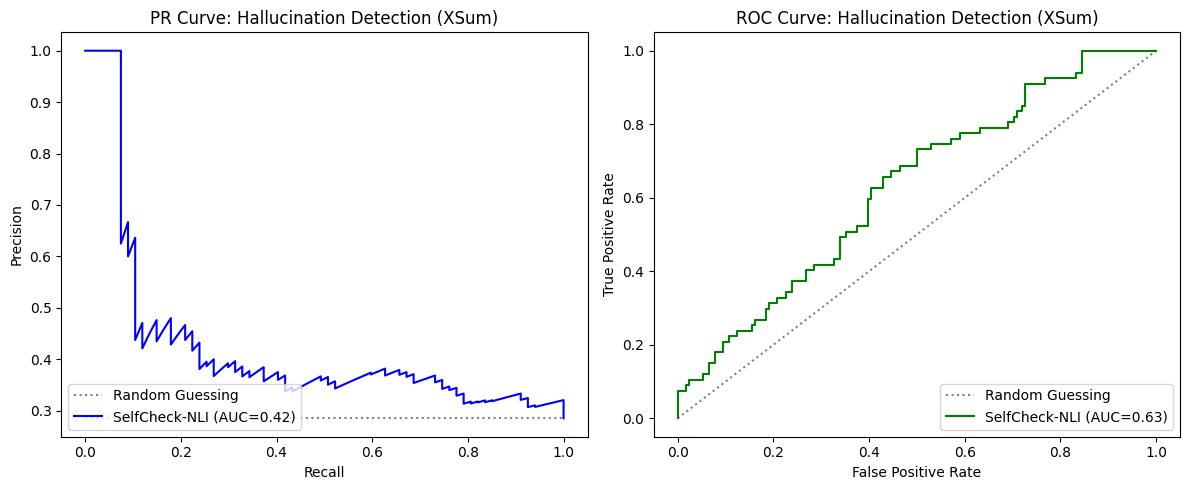

In [10]:
if len(set(xsum_y_true)) > 1:
    # Compute Metrics
    xsum_roc_auc = roc_auc_score(xsum_y_true, xsum_y_pred)
    precision_xsum, recall_xsum, _ = precision_recall_curve(xsum_y_true, xsum_y_pred)
    xsum_pr_auc = auc(recall_xsum, precision_xsum)

    # Compute ROC Curve components
    fpr_xsum, tpr_xsum, _ = roc_curve(xsum_y_true, xsum_y_pred)
    random_baseline_xsum = np.mean(xsum_y_true)

    print("\n=== XSum Existing Dataset Results ===")
    print(f"Total Sentences Evaluated: {len(xsum_y_true)}")
    print(f"XSum ROC-AUC: {xsum_roc_auc:.4f}")
    print(f"XSum PR-AUC:  {xsum_pr_auc:.4f}")

    # Plotting PR and ROC Curves Side-by-Side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # PR Curve
    ax1.hlines(y=random_baseline_xsum, xmin=0, xmax=1.0, color='grey', linestyles='dotted', label='Random Guessing')
    ax1.plot(recall_xsum, precision_xsum, '-', color='blue', label=f'SelfCheck-NLI (AUC={xsum_pr_auc:.2f})')
    ax1.set_xlabel('Recall')
    ax1.set_ylabel('Precision')
    ax1.set_title('PR Curve: Hallucination Detection (XSum)')
    ax1.legend(loc='lower left')

    # ROC Curve
    ax2.plot([0, 1], [0, 1], color='grey', linestyle='dotted', label='Random Guessing')
    ax2.plot(fpr_xsum, tpr_xsum, '-', color='green', label=f'SelfCheck-NLI (AUC={xsum_roc_auc:.2f})')
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.set_title('ROC Curve: Hallucination Detection (XSum)')
    ax2.legend(loc='lower right')

    plt.tight_layout()
    plt.show()
else:
    print("\nSkipping AUC calculation: Only one class present in LLM-Judge labels.")

# Create New Dataset

## Define Prompts (prompts.json)

In [ ]:
data = [
  {
    "id": "aus_local_001",
    "category": "transit",
    "prompt": "What are the common rules and best practices for travelling with small pets on urban public train networks?"
  },
  {
    "id": "aus_local_002",
    "category": "retail",
    "prompt": "What are standard 'change-of-mind' return policies typically found at major retail pharmacies?"
  },
  {
    "id": "aus_local_003",
    "category": "transit",
    "prompt": "What is the typical process for a passenger transferring between a metro line and a heavy rail commuter train at a major interchange station?"
  },
  {
    "id": "aus_local_004",
    "category": "retail",
    "prompt": "What types of retail items are usually strictly non-refundable due to hygiene or copyright reasons?"
  },
  {
    "id": "aus_local_005",
    "category": "local_government",
    "prompt": "How do residential street parking permit systems generally work in busy urban council areas?"
  },
  {
    "id": "aus_local_006",
    "category": "retail",
    "prompt": "What is the general process a customer must follow to claim a 'price match' or 'price beat' guarantee at a retail electronics store?"
  },
  {
    "id": "aus_local_007",
    "category": "retail",
    "prompt": "What are the typical conditions for returning power tools to a hardware store if the box has already been opened?"
  },
  {
    "id": "aus_local_008",
    "category": "retail",
    "prompt": "Do retail loyalty programs typically award points when a customer purchases third-party gift cards? Explain why or why not."
  },
  {
    "id": "aus_local_009",
    "category": "retail",
    "prompt": "Why do automotive parts stores usually refuse returns on electrical parts that have already been fitted to a vehicle?"
  },
  {
    "id": "aus_local_010",
    "category": "retail",
    "prompt": "What are the consumer rights and standard procedures when returning a faulty television to an electronics retailer?"
  },
  {
    "id": "aus_local_011",
    "category": "retail",
    "prompt": "What are a customer's options for returning a defective supermarket item if they have lost the original paper receipt?"
  },
  {
    "id": "aus_local_012",
    "category": "retail",
    "prompt": "Are customers generally allowed to return heavily discounted clearance items for a simple change of mind? Why or why not?"
  },
  {
    "id": "aus_local_013",
    "category": "retail",
    "prompt": "What is the typical maximum timeframe allowed by major department stores to return clothing purchased online?"
  },
  {
    "id": "aus_local_014",
    "category": "retail",
    "prompt": "Do major electronics retailers generally accept returns on laptops if the customer simply changes their mind after opening the box?"
  },
  {
    "id": "aus_local_015",
    "category": "retail",
    "prompt": "How can a retail cashier process a return or exchange if the item's barcode is heavily damaged and won't scan?"
  },
  {
    "id": "aus_local_016",
    "category": "transit",
    "prompt": "What times of day are generally considered 'peak hours' for public transport networks in major cities during weekdays?"
  },
  {
    "id": "aus_local_017",
    "category": "transit",
    "prompt": "Why do public transport stations located directly underneath major airports usually charge passengers a premium station access fee?"
  },
  {
    "id": "aus_local_018",
    "category": "transit",
    "prompt": "How do weekly transit reward systems work to encourage commuters to use public transport more frequently?"
  },
  {
    "id": "aus_local_019",
    "category": "transit",
    "prompt": "What architectural and navigational features help commuters easily transfer between different train lines at busy transit hubs?"
  },
  {
    "id": "aus_local_020",
    "category": "transit",
    "prompt": "How do transit authorities typically handle passenger movement when a train line is closed for weekend trackwork or maintenance?"
  },
  {
    "id": "aus_local_021",
    "category": "transit",
    "prompt": "Why do many public transit networks offer significantly cheaper daily fare caps on weekends compared to weekdays?"
  },
  {
    "id": "aus_local_022",
    "category": "transit",
    "prompt": "What are the benefits of using a public passenger ferry for commuting in a coastal or harbour city?"
  },
  {
    "id": "aus_local_023",
    "category": "transit",
    "prompt": "What happens if a commuter using a smartcard transit system forgets to 'tap off' when exiting a train station?"
  },
  {
    "id": "aus_local_024",
    "category": "transit",
    "prompt": "What role do late-night 'NightRide' bus services play in a city's public transport ecosystem?"
  },
  {
    "id": "aus_local_025",
    "category": "transit",
    "prompt": "Are bicycles allowed on the Sydney Light Rail (L2 and L3 lines) during off-peak times?"
  },
  {
    "id": "aus_local_026",
    "category": "local_government",
    "prompt": "What types of items are generally prohibited from being placed on the curb for a municipal household hard rubbish collection?"
  },
  {
    "id": "aus_local_027",
    "category": "local_government",
    "prompt": "Why do regional transport authorities require older vehicles to pass an annual safety inspection before renewing their registration?"
  },
  {
    "id": "aus_local_028",
    "category": "local_government",
    "prompt": "What are the benefits and security features of using a Digital Driver Licence on a smartphone instead of a physical plastic card?"
  },
  {
    "id": "aus_local_029",
    "category": "local_government",
    "prompt": "Under what circumstances does a used car typically require an extensive identity and safety check rather than a standard basic inspection?"
  },
  {
    "id": "aus_local_030",
    "category": "local_government",
    "prompt": "What is the maximum allowed speed limit for a P1 provisional driver (Red Ps) in NSW?"
  },
  {
    "id": "aus_local_031",
    "category": "local_government",
    "prompt": "How do you apply for Toll Relief through Service NSW, and what is the minimum annual spend required?"
  },
  {
    "id": "aus_local_032",
    "category": "local_government",
    "prompt": "What are the conditions for using a NSW Digital Driver Licence as proof of identity at a licensed venue (pub or club)?"
  },
  {
    "id": "aus_local_033",
    "category": "local_government",
    "prompt": "Under what circumstances do you need a blue slip instead of a pink slip for a vehicle in New South Wales?"
  },
  {
    "id": "aus_local_034",
    "category": "local_government",
    "prompt": "What does a sequence of three quick beeps from an E-Toll tag indicate when passing through a Sydney toll point?"
  },
  {
    "id": "aus_local_035",
    "category": "local_government",
    "prompt": "What is the penalty and demerit point deduction for using a mobile phone while driving on a full licence in NSW?"
  },
  {
    "id": "aus_local_036",
    "category": "geography_roads",
    "prompt": "What are the entry and exit points for the Lane Cove Tunnel when travelling eastbound towards the Sydney CBD?"
  },
  {
    "id": "aus_local_037",
    "category": "geography_roads",
    "prompt": "Which direction of travel on the Sydney Harbour Bridge incurs a toll, and how does the time-of-day pricing work?"
  },
  {
    "id": "aus_local_038",
    "category": "geography_roads",
    "prompt": "What is the most direct driving route from Sydney to Perisher Valley in Kosciuszko National Park?"
  },
  {
    "id": "aus_local_039",
    "category": "geography_roads",
    "prompt": "Are you required to carry snow chains when driving a 2WD sedan into Kosciuszko National Park during the winter season?"
  },
  {
    "id": "aus_local_040",
    "category": "geography_roads",
    "prompt": "What are the entry and exit points for the Lane Cove Tunnel when travelling eastbound towards the Sydney CBD?"
  },
  {
    "id": "aus_local_041",
    "category": "geography_roads",
    "prompt": "Which direction of travel on the Sydney Harbour Bridge incurs a toll, and how does the time-of-day pricing work?"
  },
  {
    "id": "aus_local_042",
    "category": "geography_roads",
    "prompt": "What is the most direct driving route from Sydney to Perisher Valley in Kosciuszko National Park?"
  },
  {
    "id": "aus_local_043",
    "category": "geography_roads",
    "prompt": "Are you required to carry snow chains when driving a 2WD sedan into Kosciuszko National Park during the winter season?"
  },
  {
    "id": "aus_local_044",
    "category": "automotive",
    "prompt": "Where and how can residents of the City of Ryde safely dispose of used engine oil from a DIY vehicle oil change?"
  },
  {
    "id": "aus_local_045",
    "category": "automotive",
    "prompt": "What specific paperwork is required by Service NSW to finalize the private sale and transfer of a used car (like a 2004 Toyota Camry)?"
  },
  {
    "id": "aus_local_046",
    "category": "automotive",
    "prompt": "Where and how can residents of the City of Ryde safely dispose of used engine oil from a DIY vehicle oil change?"
  },
  {
    "id": "aus_local_047",
    "category": "automotive",
    "prompt": "What specific paperwork is required by Service NSW to finalize the private sale and transfer of a used car (like a 2004 Toyota Camry)?"
  },
  {
    "id": "aus_local_048",
    "category": "transit",
    "prompt": "How do you transfer from the Metro M1 Line to the T9 Northern Line at Epping Station in Sydney?"
  },
  {
    "id": "aus_local_049",
    "category": "local_government",
    "prompt": "What are the requirements and costs to obtain a general boat driving licence in New South Wales?"
  },
  {
    "id": "aus_local_050",
    "category": "geography_roads",
    "prompt": "What is the vehicle entry fee for the Royal National Park in NSW, and how long does a day pass last?"
  }
]

filename = "prompts.json"

with open(filename, "w", encoding="utf-8") as file:
    json.dump(data, file, indent=2, ensure_ascii=False)

print(f"Successfully generated {filename} with {len(data)} generalized prompts.")

Successfully generated prompts.json with 50 generalized prompts.


### Automated Generation Script

In [ ]:
# 1. Update generate_text to accept num_samples and process them in a batch
def generate_text(prompt: str, temperature: float, top_p: float = 0.9, max_new_tokens: int = 250, num_samples: int = 1):
    messages = [{"role": "user", "content": prompt}]
    formatted_prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)

    do_sample = temperature > 0.0

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature if do_sample else None,
            top_p=top_p if do_sample else None,
            num_return_sequences=num_samples, # Added to batch generation
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode all returned sequences
    responses = [
        tokenizer.decode(out[inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()
        for out in outputs
    ]

    # Return a single string if 1 sample, else return the list
    return responses[0] if num_samples == 1 else responses

def build_dataset(prompts_file: str, output_file: str, num_samples: int = 5):
    with open(prompts_file, "r") as f:
        prompts_data = json.load(f)

    dataset = []

    for idx, item in enumerate(prompts_data, 1):
        prompt_text = item["prompt"]
        print(f"[{idx}/{len(prompts_data)}] Processing Prompt")

        # 1. Generate Main Response (Greedy / Deterministic)
        main_passage = generate_text(prompt_text, temperature=0.0, num_samples=1)

        # 2. Split Main Response into Sentences
        doc = nlp(main_passage)
        sentences = [sent.text.strip() for sent in doc.sents if len(sent.text.strip()) > 0]

        # 3. Generate Stochastic Samples (High Temperature)
        # REMOVED the for-loop. We now generate all samples in one function call.
        samples = generate_text(prompt_text, temperature=1.0, top_p=0.95, num_samples=num_samples)

        dataset.append({
            "id": item["id"],
            "category": item.get("category", "general"),
            "prompt": prompt_text,
            "passage": main_passage,
            "sentences": sentences,
            "samples": samples,
            "ground_truth_labels": []  # To be populated during annotation
        })

    with open(output_file, "w") as f:
        json.dump(dataset, f, indent=2)

    print(f"\nDataset generation complete! Saved to {output_file}")

if __name__ == "__main__":
    build_dataset(
        prompts_file="prompts.json",
        output_file="constructed_dataset_raw.json",
        num_samples=5
    )

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[1/50] Processing Prompt: What are the common rules and best practices for t...
[2/50] Processing Prompt: What are standard 'change-of-mind' return policies...
[3/50] Processing Prompt: What is the typical process for a passenger transf...
[4/50] Processing Prompt: What types of retail items are usually strictly no...
[5/50] Processing Prompt: How do residential street parking permit systems g...
[6/50] Processing Prompt: What is the general process a customer must follow...
[7/50] Processing Prompt: What are the typical conditions for returning powe...
[8/50] Processing Prompt: Do retail loyalty programs typically award points ...
[9/50] Processing Prompt: Why do automotive parts stores usually refuse retu...
[10/50] Processing Prompt: What are the consumer rights and standard procedur...
[11/50] Processing Prompt: What are a customer's options for returning a defe...
[12/50] Processing Prompt: Are customers generally allowed to return heavily ...
[13/50] Processing Prompt: What is th

## Data Annotation

### Interactive CLI Annotation Tool (To Manually Annotate)
This script helps to manually review each sentence in the passage, cross-check against verified facts, and assign standard binary hallucination labels ($0$ for accurate, $1$ for hallucinated/unsupported)

In [ ]:
def run_annotation(input_file: str, output_file: str):
    with open(input_file, "r") as f:
        dataset = json.load(f)

    print("=" * 60)
    print("SelfCheckGPT Dataset Interactive Annotation Tool")
    print("Instructions: Enter 0 for FACTUAL, 1 for HALLUCINATED")
    print("=" * 60)

    for entry in dataset:
        print(f"\nID: {entry['id']} | Category: {entry['category']}")
        print(f"PROMPT: {entry['prompt']}\n")
        print("PASSAGE TO ANNOTATE:")

        labels = []
        for idx, sentence in enumerate(entry["sentences"]):
            print(f"  [{idx + 1}] {sentence}")
            while True:
                user_input = input("      Is this sentence hallucinated? (0 = Factual / 1 = Hallucination): ").strip()
                if user_input in ["0", "1"]:
                    labels.append(int(user_input))
                    break
                print("      Invalid input. Enter 0 or 1.")

        entry["ground_truth_labels"] = labels
        print("-" * 50)

    with open(output_file, "w") as f:
        json.dump(dataset, f, indent=2)

    print(f"\nAnnotation complete! Fully labeled dataset saved to {output_file}")

if __name__ == "__main__":
    run_annotation(
        input_file="constructed_dataset_raw.json",
        output_file="constructed_dataset_annotated.json"
    )

### Human Annotation - 1

In [ ]:
# 0 = Factual / Standard Refusal, 1 = Hallucination / Factually Incorrect
annotations_1 = {
    "aus_local_001": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
    "aus_local_002": [0, 0, 0, 0, 0, 0],
    "aus_local_003": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_004": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_005": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_006": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_007": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_008": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_009": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_010": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_011": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_012": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_013": [0, 0, 0, 0],
    "aus_local_014": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_015": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_016": [0, 0, 0, 0, 0, 0, 0],
    "aus_local_017": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_018": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_019": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_020": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_021": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_022": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_023": [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    "aus_local_024": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_025": [1, 1, 1, 0, 0, 1, 0, 0],
    "aus_local_026": [0, 0, 0],
    "aus_local_027": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_028": [0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_029": [0, 0],
    "aus_local_030": [1, 0, 0],
    "aus_local_031": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_032": [0, 0, 0, 0, 1, 0, 0, 1, 0],
    "aus_local_033": [0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1],
    "aus_local_034": [1, 1, 0, 1, 1, 1, 1, 0],
    "aus_local_035": [0, 1, 1, 1, 1, 0, 0],
    "aus_local_036": [1, 1, 0, 1, 1, 1],
    "aus_local_037": [1, 1, 0],
    "aus_local_038": [1, 0, 0, 1, 1, 1, 0, 1, 0],
    "aus_local_039": [1, 1, 0, 0],
    "aus_local_040": [1, 1, 0, 1, 1, 1],
    "aus_local_041": [1, 1, 0],
    "aus_local_042": [1, 0, 0, 1, 1, 1, 0, 1, 0],
    "aus_local_043": [1, 1, 0, 0],
    "aus_local_044": [0, 0, 0],
    "aus_local_045": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    "aus_local_046": [0, 0, 0],
    "aus_local_047": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    "aus_local_048": [0, 0, 0, 1, 1, 0, 0, 0],
    "aus_local_049": [0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0],
    "aus_local_050": [0, 0, 0]
}

### Human Annotation - 2

In [ ]:
annotations_2 = {
    "aus_local_001": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
    "aus_local_002": [0, 0, 0, 0, 0, 0],
    "aus_local_003": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_004": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_005": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_006": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_007": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_008": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_009": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_010": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_011": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_012": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_013": [0, 0, 0, 0],
    "aus_local_014": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_015": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_016": [0, 0, 0, 0, 0, 0, 0],
    "aus_local_017": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_018": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_019": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_020": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_021": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_022": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_023": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_024": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_025": [0, 0, 1, 1, 1, 1, 1, 0],
    "aus_local_026": [1, 1, 0],
    "aus_local_027": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_028": [0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_029": [0, 0],
    "aus_local_030": [1, 0, 0],
    "aus_local_031": [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_032": [0, 0, 0, 0, 0, 0, 0, 0, 0],
    "aus_local_033": [1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1],
    "aus_local_034": [1, 1, 0, 1, 1, 1, 1, 0],
    "aus_local_035": [0, 1, 1, 1, 0, 0, 0],
    "aus_local_036": [1, 1, 1, 1, 1, 1],
    "aus_local_037": [1, 1, 0],
    "aus_local_038": [1, 0, 0, 1, 1, 1, 1, 1, 0],
    "aus_local_039": [1, 1, 0, 0],
    "aus_local_040": [1, 1, 1, 1, 1, 1],
    "aus_local_041": [1, 1, 0],
    "aus_local_042": [1, 0, 0, 1, 1, 1, 1, 1, 0],
    "aus_local_043": [1, 1, 0, 0],
    "aus_local_044": [0, 0, 0],
    "aus_local_045": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    "aus_local_046": [0, 0, 0],
    "aus_local_047": [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1],
    "aus_local_048": [0, 0, 0, 1, 1, 0, 0, 0],
    "aus_local_049": [0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1],
    "aus_local_050": [0, 0, 0]
}

### Measure of Agreement (Annotations - Day 1 vs Annotations - Day 2)

In [ ]:

labels_flat_1 = []
labels_flat_2 = []

for prompt_id, human_binary_1 in annotations_1.items():
        human_binary_2 = annotations_2[prompt_id]

        # 4. Append to flat lists (enforcing equal length just in case of sentence mismatches)
        min_len = min(len(human_binary_1), len(human_binary_2))
        labels_flat_1.extend(human_binary_1[:min_len])
        labels_flat_2.extend(human_binary_2[:min_len])

In [ ]:

# Calculate Cohen's Kappa
kappa_score = cohen_kappa_score(labels_flat_1, labels_flat_2)

# Print the final report for your assignment
print("\n" + "=" * 50)
print("MEASURE OF AGREEMENT (Annotations - 1 vs Annotations - 2)")
print("=" * 50)
print(f"Total Sentences Evaluated: {len(labels_flat_1)}")
print(f"Cohen's Kappa Score: {kappa_score:.4f}")

# Provide the standard academic interpretation scale for your report
if kappa_score > 0.8:
    print("Interpretation: Almost Perfect Agreement")
elif kappa_score > 0.6:
    print("Interpretation: Substantial Agreement")
elif kappa_score > 0.4:
    print("Interpretation: Moderate Agreement")
elif kappa_score > 0.2:
    print("Interpretation: Fair Agreement")
else:
    print("Interpretation: Slight or Poor Agreement")
print("=" * 50)


MEASURE OF AGREEMENT (Annotations - 1 vs Annotations - 2)
Total Sentences Evaluated: 480
Cohen's Kappa Score: 0.8650
Interpretation: Almost Perfect Agreement


### Human Annoted Results Merging with Dataset

In [ ]:
# 2. Inject labels into your raw dataset
with open("constructed_dataset_raw.json", "r", encoding="utf-8") as file:
    dataset = json.load(file)

for entry in dataset:
    if entry["id"] in annotations_1:
        entry["ground_truth_labels"] = annotations_1[entry["id"]]

# 3. Export the completed annotated dataset
with open("constructed_dataset_annotated.json", "w", encoding="utf-8") as file:
    json.dump(dataset, file, indent=2, ensure_ascii=False)

print("Annotation complete! The full dataset has been saved to constructed_dataset_annotated.json")

Annotation complete! The full dataset has been saved to constructed_dataset_annotated.json


## Dataset Snippet

In [ ]:
def generate_report_snippets(dataset_json_path, num_samples=5):
    """
    Formats the constructed dataset into a clean DataFrame for report figures.
    """
    with open(dataset_json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    snippet_data = []
    for item in data[:num_samples]:
        snippet_data.append({
            "Prompt ID": item["id"],
            "Category": item["category"],
            "Passage (Truncated)": item["passage"][:150] + "...",
            "Sentences Count": len(item.get("sentences", [])),
            "Ground Truth": str(item.get("ground_truth_labels", []))
        })

    df_snippets = pd.DataFrame(snippet_data)
    print("=== Take a screenshot of this table for your 'Construction of new data' section ===")
    display(df_snippets)

generate_report_snippets("constructed_dataset_annotated.json")

=== Take a screenshot of this table for your 'Construction of new data' section ===


,Prompt ID,Category,Passage (Truncated),Sentences Count,Ground Truth
0,aus_local_001,transit,Travelling with small pets on urban public tra...,15,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0]"
1,aus_local_002,retail,"I'm sorry, but I can't answer this question. T...",6,"[0, 0, 0, 0, 0, 0]"
2,aus_local_003,transit,The typical process for a passenger transferri...,11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
3,aus_local_004,retail,Retail items that are typically considered str...,10,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
4,aus_local_005,local_government,Residential street parking permit systems typi...,13,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"


## Run SelfCheckGPT on New Dataset

In [ ]:
def load_local_dataset(filepath: str):
    """Loads the dataset from a JSON file."""
    with open(filepath, "r") as f:
        return json.load(f)

In [ ]:
def generate_predictions(dataset, model):
    """Generates predictions and safely aligns them with ground truth labels."""
    all_pred_scores = []
    all_true_labels = []

    for item in dataset:
        sentences = item.get("sentences", [])
        samples = item.get("samples", [])
        ground_truth = item.get("ground_truth_labels", [])

        if not sentences or not ground_truth:
            continue

        # Predict sentence-level hallucination probabilities
        sent_scores = model.predict(
            sentences=sentences,
            sampled_passages=samples,
        )

        # Convert to list for JSON serialization and easier handling
        scores_list = sent_scores.tolist()
        item["predicted_scores"] = scores_list

        # SAFEGUARD: Prevent sklearn ValueError by aligning lengths
        min_len = min(len(scores_list), len(ground_truth))
        if len(scores_list) != len(ground_truth):
            print(f"Warning: Length mismatch in ID {item['id']}. Truncating to {min_len} items.")

        valid_scores = scores_list[:min_len]
        valid_truth = ground_truth[:min_len]

        all_pred_scores.extend(valid_scores)
        all_true_labels.extend(valid_truth)

        # Print item-level results
        print(f"\nPrompt ID: {item['id']}")
        for sent, score, label in zip(sentences[:min_len], valid_scores, valid_truth):
            print(f"  Score: {score:.4f} | Truth: {label} | Sent: {sent[:60]}...")

    return all_true_labels, all_pred_scores

In [1]:
def evaluate_metrics(y_true, y_pred):
    """Calculates and prints AUC performance metrics."""
    if len(set(y_true)) > 1:
        roc_auc = roc_auc_score(y_true, y_pred)
        precision, recall, _ = precision_recall_curve(y_true, y_pred)
        pr_auc = auc(recall, precision)

        fpr, tpr, _ = roc_curve(y_true, y_pred)
        random_baseline = np.mean(y_true)

        print("\n" + "=" * 50)
        print("EVALUATION RESULTS ON CONSTRUCTED DATASET")
        print(f"Total Sentences Evaluated: {len(y_true)}")
        print(f"ROC-AUC Score: {roc_auc:.4f}")
        print(f"PR-AUC Score:  {pr_auc:.4f}")
        print("=" * 50)
        return (roc_auc, pr_auc, precision, recall,
                fpr, tpr, random_baseline)
    else:
        print("\nNote: Need both positive (1) and negative (0) labels in ground truth to calculate AUC metrics.")
        return None

In [ ]:
dataset_file = "constructed_dataset_annotated.json"
dataset = load_local_dataset(dataset_file)

# Predict
# Pass initialized model (selfcheck_nli) into the function
y_true, y_pred = generate_predictions(dataset, selfcheck_nli)
print("y_true---\n",y_true)
print("y_pred---\n",y_pred)


Prompt ID: aus_local_001
  Score: 0.0900 | Truth: 0 | Sent: Travelling with small pets on urban public trains can be cha...
  Score: 0.2230 | Truth: 0 | Sent: Here are some general guidelines and best practices that mig...
  Score: 0.2595 | Truth: 0 | Sent: **Check Train Policies**: Before you travel, check if your c...
  Score: 0.3007 | Truth: 0 | Sent: Some cities have strict policies regarding pet transport....
  Score: 0.2926 | Truth: 0 | Sent: 2. **Pet Size and Weight Limits**: Ensure your pet fits with...
  Score: 0.7902 | Truth: 0 | Sent: This is crucial as exceeding these limits could result in fi...
  Score: 0.4775 | Truth: 0 | Sent: 3. **Comfortable Travel Gear**: Pack items like a carrier, l...
  Score: 0.3565 | Truth: 0 | Sent: Make sure everything is securely packed so it doesn't move a...
  Score: 0.5317 | Truth: 0 | Sent: 4....
  Score: 0.3991 | Truth: 1 | Sent: **Travel Insurance**: Consider purchasing travel insurance t...
  Score: 0.5063 | Truth: 1 | Sent: This can p

In [6]:
custom_metrics = evaluate_metrics(y_true, y_pred)


EVALUATION RESULTS ON CONSTRUCTED DATASET
Total Sentences Evaluated: 481
ROC-AUC Score: 0.7775
PR-AUC Score:  0.4106


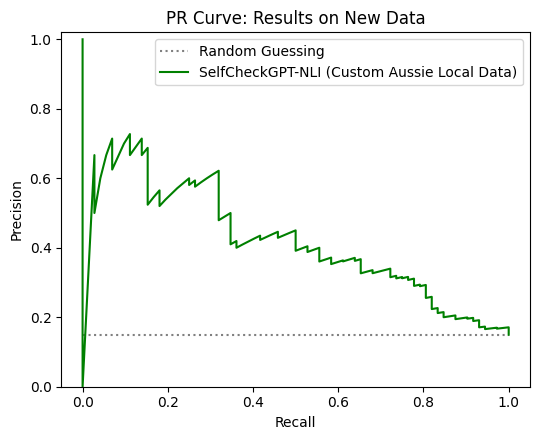

In [ ]:
def plot_custom_dataset_results(y_true, y_pred, dataset_name="Custom Aussie Local Data"):
    """
    Plots the PR curve for the newly constructed dataset.
    """
    if len(set(y_true)) > 1:
        precision_custom, recall_custom, _ = precision_recall_curve(y_true, y_pred)
        random_baseline_custom = np.mean(y_true)

        plt.figure(figsize=(5.5, 4.5))
        plt.hlines(y=random_baseline_custom, xmin=0, xmax=1.0, color='grey', linestyles='dotted', label='Random Guessing')
        plt.plot(recall_custom, precision_custom, '-', color='green', label=f'SelfCheckGPT-NLI ({dataset_name})')
        plt.legend()
        plt.ylim(0.0, 1.02)
        plt.ylabel("Precision")
        plt.xlabel("Recall")
        plt.title(f"PR Curve: Results on New Data")
        plt.tight_layout()
        plt.show()
    else:
        print("Cannot plot PR curve: Ground truth lacks both positive and negative labels.")

plot_custom_dataset_results(y_true, y_pred)

# Cross-Domain Comparative Analysis : XSum vs New Data

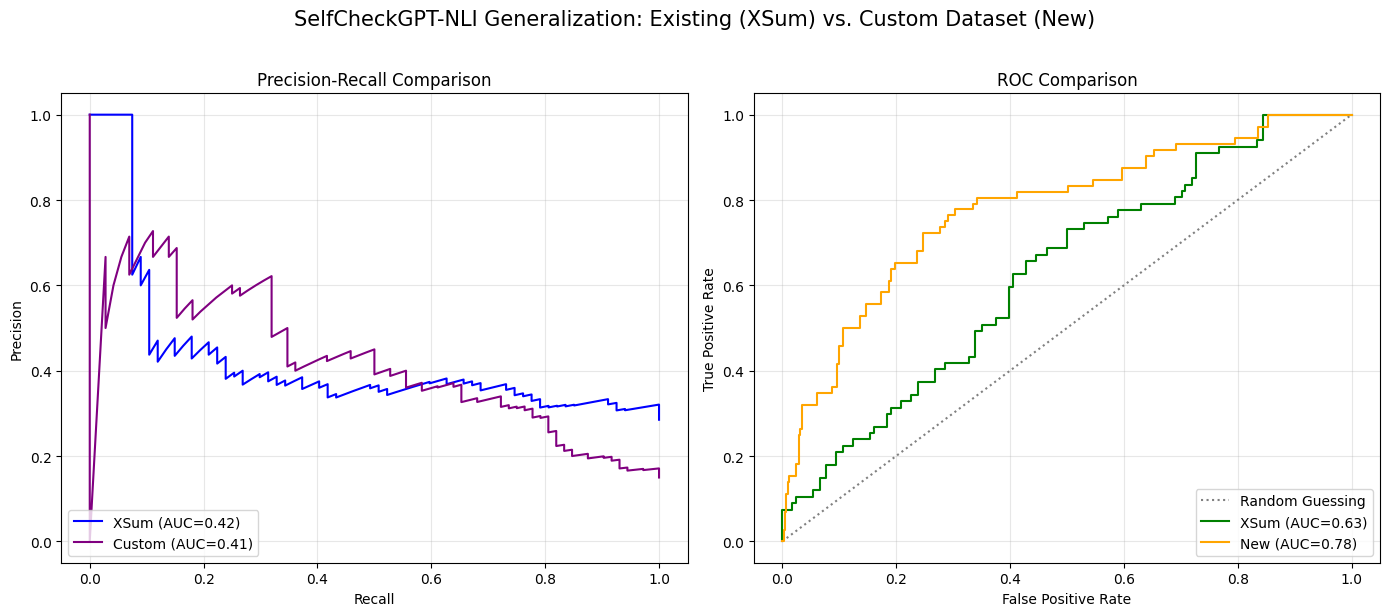

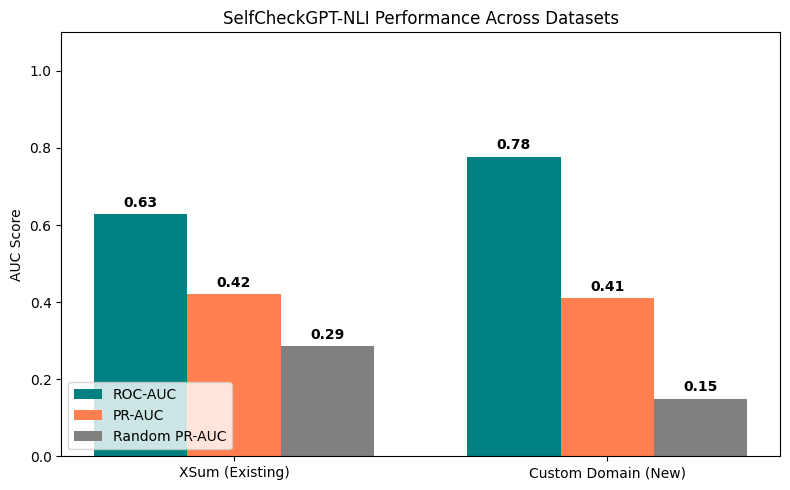

In [16]:
if custom_metrics is not None and len(set(xsum_y_true)) > 1:
    (custom_roc_auc, custom_pr_auc, precision_custom, recall_custom,
     fpr_custom, tpr_custom, random_baseline_custom) = custom_metrics

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('SelfCheckGPT-NLI Generalization: Existing (XSum) vs. Custom Dataset (New)', fontsize=15, y=1.02)

    # 1. Comparative PR Curve
    ax1.plot(recall_xsum, precision_xsum, '-', color='blue', label=f'XSum (AUC={xsum_pr_auc:.2f})')
    ax1.plot(recall_custom, precision_custom, '-', color='purple', label=f'Custom (AUC={custom_pr_auc:.2f})')
    ax1.set_xlabel('Recall')
    ax1.set_ylabel('Precision')
    ax1.set_title('Precision-Recall Comparison')
    ax1.legend(loc='lower left')
    ax1.grid(alpha=0.3)

    # 2. Comparative ROC Curve
    ax2.plot([0, 1], [0, 1], color='grey', linestyle='dotted', label='Random Guessing')
    ax2.plot(fpr_xsum, tpr_xsum, '-', color='green', label=f'XSum (AUC={xsum_roc_auc:.2f})')
    ax2.plot(fpr_custom, tpr_custom, '-', color='orange', label=f'New (AUC={custom_roc_auc:.2f})')
    ax2.set_xlabel('False Positive Rate')
    ax2.set_ylabel('True Positive Rate')
    ax2.set_title('ROC Comparison')
    ax2.legend(loc='lower right')
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    datasets = ['XSum (Existing)', 'Custom Domain (New)']
    roc_scores = [xsum_roc_auc, custom_roc_auc]
    pr_scores = [xsum_pr_auc, custom_pr_auc]
    random_baselines = [random_baseline_xsum, random_baseline_custom]

    x = np.arange(len(datasets))
    width = 0.25  # Narrower width to fit 3 bars per group

    fig, ax = plt.subplots(figsize=(8, 5))
    rects1 = ax.bar(x - width, roc_scores, width, label='ROC-AUC', color='teal')
    rects2 = ax.bar(x, pr_scores, width, label='PR-AUC', color='coral')
    rects3 = ax.bar(x + width, random_baselines, width, label='Random PR-AUC', color='grey')

    ax.set_ylabel('AUC Score')
    ax.set_title('SelfCheckGPT-NLI Performance Across Datasets')
    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.legend(loc='lower left')
    ax.set_ylim(0, 1.1)

    # Auto-label bars with exact scores
    for rect in rects1 + rects2 + rects3:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()